In [ ]:
import numpy as np
import astropy.units as u
from lifesimmc.core.modules.processing.matched_filter_module import MatchedFilterModule
from matplotlib import pyplot as plt
from phringe.core.scene import Scene
from phringe.core.instrument import Instrument
from phringe.core.observation import Observation
from phringe.core.sources.exozodi import Exozodi
from phringe.core.sources.local_zodi import LocalZodi
from phringe.core.sources.planet import Planet
from phringe.core.sources.star import Star
from phringe.io.sed_loader import SEDLoader

from scipy.stats import ncx2, norm
from matplotlib.colors import LogNorm, SymLogNorm

from phringe.lib.array_configuration import XArrayConfiguration, SBWConfiguration
from phringe.lib.baseline import OptimalNullingBaseline
from phringe.lib.beam_combiner import DoubleBracewell, SingleBracewell
from phringe.core.perturbations.power_law_psd_perturbation import PowerLawPSDPerturbation

from lifesimmc.core.modules.generating.data_generation_module import DataGenerationModule
from lifesimmc.core.modules.generating.template_generation_module import TemplateGenerationModule
from lifesimmc.core.modules.loading.setup_module import SetupModule
from lifesimmc.core.modules.processing.energy_detector_test_module import EnergyDetectorTestModule
from lifesimmc.core.modules.processing.ml_parameter_estimation_module import MLSEDEstimationModule
from lifesimmc.core.modules.processing.neyman_pearson_test_module import NeymanPearsonTestModule
from lifesimmc.core.modules.processing.variance_normalization_module import NoiseVarianceNormalizationModule
from lifesimmc.core.modules.processing.zca_whitening_module import ZCAWhiteningModule 
from lifesimmc.core.modules.processing.highpass_filter_module import HighPassFilterModule


from lifesimmc.core.pipeline import Pipeline
from lifesimmc.lib.colormaps import cmap_blue
from lifesimmc.lib.instrument import LIFEReferenceDesign, InstrumentalNoise
from lifesimmc.lib.observation import LIFEReferenceObservation

from torch import mean, var, cov


In [2]:
# Use the predefined ideal LIFE baseline instrument, i.e. without any instrumental noise
inst = inst = Instrument(
    array_configuration_matrix=SBWConfiguration.acm,
    complex_amplitude_transfer_matrix=SingleBracewell.catm,
    kernels=SingleBracewell.kernels,
    aperture_diameter=3 * u.m,
    nulling_baseline_min=8 * u.m,
    nulling_baseline_max=100 * u.m,
    throughput=0.12,
    quantum_efficiency=0.7,
    spectral_resolving_power=20,
    wavelength_min=4 * u.um,
    wavelength_max=18.5 * u.um,
    wavelength_bands_boundaries=[],  # Alternatively e.g. ['9 um']
    #amplitude_perturbation=PowerLawPSDPerturbation(coefficient=1, rms=0.000001 * u.percent),
    #phase_perturbation=PowerLawPSDPerturbation(coefficient=1, rms=0.000015 * u.nm, chromatic=True),
    #polarization_perturbation=PowerLawPSDPerturbation(coefficient=1, rms=0.000001 * u.rad)
    amplitude_perturbation=None,
    phase_perturbation=None,
    polarization_perturbation=None
)



# User the predefined observation for the LIFE baseline design
obs = Observation(
    solar_ecliptic_latitude=0 * u.deg,  # Alternatively: '0 deg' or 0
    total_integration_time='10 d',  # Alternatively: '1 d' or 86400
    detector_integration_time='6000 s',  # Alternatively: '600 s' or 600
    modulation_period=10* u.day,  # Alternatively: '1 d' or 86400
    nulling_baseline=20
)


In [3]:
scene = Scene()

# Create star
star = Star(
    name='Sun Twin',
    distance='10 pc',
    mass='1 Msun',
    radius='1 Rsun',
    temperature='5778 K',
    right_ascension='10 hourangle',
    declination='45 deg',
)



sed_loader = SEDLoader(
    path_to_file='spectra/earth.txt', # Alternatively: None
    #sed=None, # Alternatively: NumPy array containing the sed
    #wavelengths=None, # Alternatively: NumPy array containing the wavelengths
    sed_units='W/sr/m2/um', # Alternatively: u.W / u.sr / u.m**2 / u.um
    wavelength_units='um', # Alternatively: u.um
    #observed_planet_radius=None, # Only required if sed_units are not given per solid angle, i.e. /sr
    #observed_host_star_distance=None # Only required if sed_units are not given per solid angle, i.e. /sr
    )

# Create planet
earth_twin = Planet(
    name='Earth Twin',
    propagate_orbit=False,
    #sed_loader=SEDLoader(path_to_file='../_static/psg_earth_spectrum.txt', sed_units='W/sr/m2/um',  wavelength_units='um'),
    sed_loader = sed_loader,
    mass='1 Mearth',
    radius='1 Rearth',
    temperature='254 K',
    semi_major_axis='1 au',
    eccentricity=0.,
    inclination='180 deg',
    raan='90 deg',
    argument_of_periapsis='0 deg',
    true_anomaly='135 deg',
)




# Create local zodi
local_zodi = LocalZodi()

# Create exozodi
exozodi = Exozodi(
    level=10, 
    inclination='0 deg',
    raan='135 deg')

# Add sources to scene
scene.add_source(star)
scene.add_source(local_zodi)
scene.add_source(exozodi)
scene.add_source(earth_twin)

In [4]:
# Create the pipeline
pipeline = Pipeline(gpu_index=2, seed=42, grid_size=60)


# Setup the simulation
module = SetupModule(
    n_setup_out='setup',
    n_planets_out='params_init',
    instrument=inst,
    observation=obs,
    scene=scene
)
pipeline.add_module(module)


pipeline.run()




Loading setup...
Done


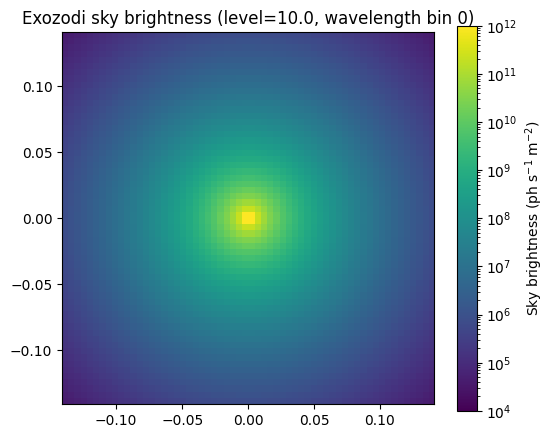

9.61993e+11
Exozodi level: 10.0


In [5]:
# Sanity-check the exozodi model directly: plot its sky brightness distribution
# and print its max/sum so we can see whether `level` actually changes anything
# before it gets processed (nulled, whitened, etc.) by the rest of the pipeline.
sky_brightness = exozodi.sky_brightness_distribution  # shape: n_wavelengths x n_time x n_grid x n_grid
wl_index = 0  # which wavelength bin to visualize
fov = exozodi._phringe._instrument._field_of_view  * 180 * 3600 / np.pi




plt.figure(figsize=(6, 5))
plt.imshow(sky_brightness[wl_index, 0].cpu().numpy(), 
           origin='upper', cmap='viridis',
           extent = (-fov[wl_index]/2, fov[wl_index]/2, -fov[wl_index]/2, fov[wl_index]/2),
           norm = 'log',
           vmax = 1e12, vmin = 1e4
           )
plt.colorbar(label='Sky brightness (ph s$^{-1}$ m$^{-2}$)')
plt.title(f'Exozodi sky brightness (level={exozodi.level}, wavelength bin {wl_index})')
#plt.plot(xs, ys_inc)
#plt.savefig('plots/exozodi.png', dpi = 300, transparent = True)
plt.show()
print(np.max(sky_brightness[wl_index, 0].cpu().numpy()))


print('Exozodi level:', exozodi.level)

In [6]:
module = DataGenerationModule(n_setup_in='setup', n_data_out='data')
pipeline.add_module(module)

module = TemplateGenerationModule(n_setup_in='setup', n_template_out='temp', fov=1e-6)
pipeline.add_module(module)

'''
module = HighPassFilterModule(
                n_data_in='data',
                n_template_in='temp',
                n_data_out='data_filtered',
                n_template_out='temp_filtered',
                n_transformation_out='highpass',
                n_frequencies=1,
            )
pipeline.add_module(module)
'''

module = ZCAWhiteningModule(
                n_setup_in='setup',
                n_data_in='data',
                n_template_in='temp',
                n_data_out='data_filtered_white',
                n_template_out='temp_filtered_white',
                n_transformation_out='zca_filtered',
                diagonal_only=False,
                subtract_mean=True
            )
pipeline.add_module(module)


module = ZCAWhiteningModule(
                n_setup_in='setup',
                n_data_in='data',
                n_template_in='temp',
                n_data_out='data_white',
                n_template_out='temp_white',
                n_transformation_out='zca',
                diagonal_only=False,
                subtract_mean=False
            )
pipeline.add_module(module)


pipeline.run()

Output()

Done
Generating templates...
Done
Applying ZCA whitening...
Done
Applying ZCA whitening...
Done


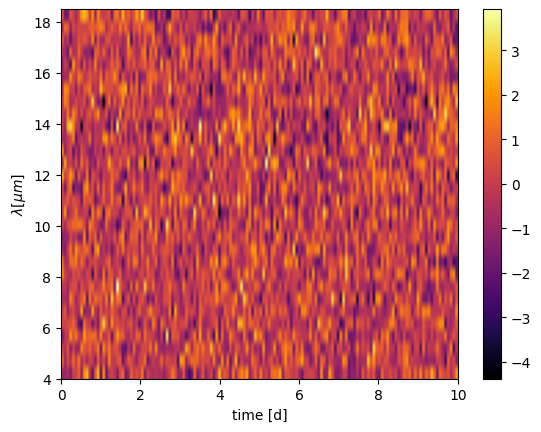

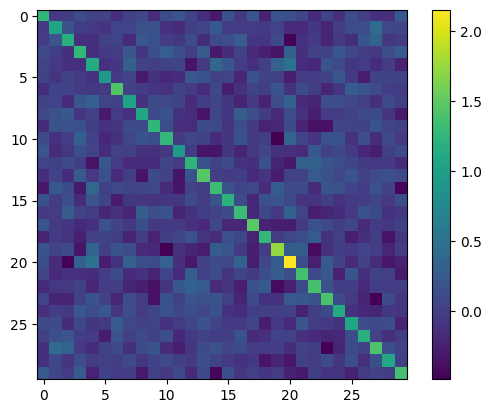

In [7]:
data = pipeline.get_resource('data_filtered_white').get_data()[0]
plt.figure()
plt.imshow(data,  cmap='inferno', origin = 'lower',  extent = [0, 10, 4, 18.5], aspect = 'auto')
plt.colorbar()
plt.xlabel("time [d]")
plt.ylabel(r"$\lambda [\mu m]$")
#plt.savefig("plots/data_white.png", transparent = True, dpi = 300)
plt.show()
plt.close()

plt.figure()
cov_data = cov(data)
plt.imshow(cov_data, origin = 'upper')
plt.colorbar()


Calculating correlation map...
Done


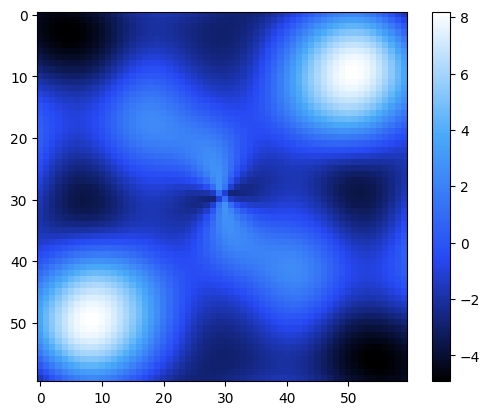

In [8]:
# Generate the correlation map
module = MatchedFilterModule(n_data_in='data_filtered_white', n_template_in='temp_filtered_white', n_image_out='imag_corr')
pipeline.add_module(module)
pipeline.run()

# Get the correlation map from the image resource
imag_corr = pipeline.get_resource('imag_corr').get_image(as_numpy=True)

# Plot the image
plt.imshow(imag_corr, cmap=cmap_blue)
plt.colorbar()
#plt.savefig("plots/corr_map_white.png", transparent = True, dpi = 300)
plt.show()
plt.close()

<>:49: SyntaxWarning: invalid escape sequence '\s'
<>:69: SyntaxWarning: invalid escape sequence '\m'
<>:71: SyntaxWarning: invalid escape sequence '\m'
<>:49: SyntaxWarning: invalid escape sequence '\s'
<>:69: SyntaxWarning: invalid escape sequence '\m'
<>:71: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_25160/3020311965.py:49: SyntaxWarning: invalid escape sequence '\s'
  label='1$\sigma$',
/tmp/ipykernel_25160/3020311965.py:69: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('SED (ph s$^{-1}$ m$^{-2}$ $\mu$m$^{-1}$)')
/tmp/ipykernel_25160/3020311965.py:71: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Wavelength ($\mu$m)')


Output()

Done


'\n\n\nplt.ylim(-0.2, 0.6)\nplt.legend()\nplt.show()\n'

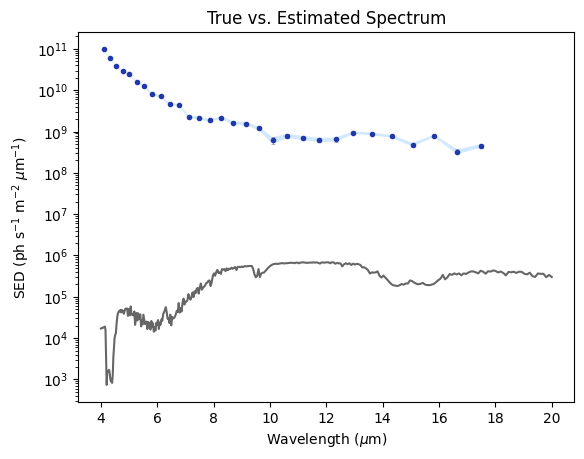

In [9]:

module = MLSEDEstimationModule(
    n_setup_in='setup',
    n_data_in='data_white',
    n_template_in='temp_white',
    n_transformation_in='zca',
    n_planets_in='params_init',
    n_planets_out='params_ml',
)
pipeline.add_module(module)
pipeline.run()

# Get the initial (input) parameters so we can plot the input spectrum (spectral energy distribution; SED) as a reference
params_init = pipeline.get_resource('params_init')
params_ml = pipeline.get_resource('params_ml')

sed_init = params_init.collection[0].planet.sed_loader.sed #  W / (sr um m2)
sed_estimated = params_ml.collection[0].sed
sed_err = params_ml.collection[0].std
sed_cov = params_ml.collection[0].cov




wavelengths = inst._get_wavelength_bins()[0] * 1e6
wavelengths_init = np.logspace(np.log10(4), np.log10(20), len(sed_init))


# Plot everything
plt.errorbar(
    wavelengths,
    sed_estimated,
    yerr=sed_err,
    fmt='none',
    ecolor='gray',
    alpha=0.8,
    zorder=1,
    capsize=1.5,
    capthick=0.5,
    linewidth=0.5
)
plt.fill_between(
    wavelengths,
    sed_estimated - sed_err,
    sed_estimated + sed_err,
    color='dodgerblue',
    edgecolor=None,
    lw=0,
    alpha=0.2,
    label='1$\sigma$',
    zorder=0
)

hc = 1.986446e-25 # Jm 
#sed_init*hc = # W / (sr um m2) * Jm


#self._instrument.wavelength_bin_centers.cpu().numpy()


planet_radius = pipeline.get_resource('params_init').collection[0].planet.radius # m
system_distance = scene.star.distance # m
sed_init_observed = sed_init*planet_radius**2  / system_distance**2 * np.pi
# 1e-19

plt.scatter(wavelengths, sed_estimated, label='Data', color="xkcd:sapphire", zorder=2, marker='.')
plt.plot(wavelengths_init, sed_init_observed , label='True', linestyle='-', color='black', alpha=0.6, zorder=1)
plt.yscale('log')

plt.ylabel('SED (ph s$^{-1}$ m$^{-2}$ $\mu$m$^{-1}$)')
plt.title('True vs. Estimated Spectrum')
plt.xlabel('Wavelength ($\mu$m)')
'''


plt.ylim(-0.2, 0.6)
plt.legend()
plt.show()
'''

Output()

<>:60: SyntaxWarning: invalid escape sequence '\s'
<>:80: SyntaxWarning: invalid escape sequence '\m'
<>:82: SyntaxWarning: invalid escape sequence '\m'
<>:60: SyntaxWarning: invalid escape sequence '\s'
<>:80: SyntaxWarning: invalid escape sequence '\m'
<>:82: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_25160/3814759080.py:60: SyntaxWarning: invalid escape sequence '\s'
  label='1$\sigma$',
/tmp/ipykernel_25160/3814759080.py:80: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('SED (ph s$^{-1}$ m$^{-2}$ $\mu$m$^{-1}$)')
/tmp/ipykernel_25160/3814759080.py:82: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Wavelength ($\mu$m)')


Done


'\n\n\nplt.ylim(-0.2, 0.6)\nplt.legend()\nplt.show()\n'

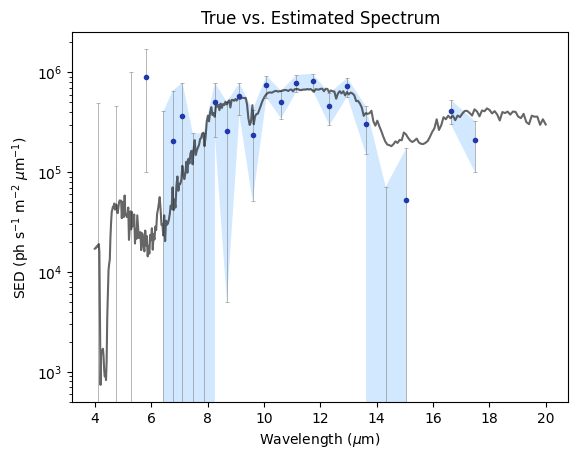

In [10]:

module = MLSEDEstimationModule(
    n_setup_in='setup',
    n_data_in='data_filtered_white',
    n_template_in='temp_filtered_white',
    n_transformation_in='zca_filtered',
    n_planets_in='params_init',
    n_planets_out='params_ml',
)
pipeline.add_module(module)
pipeline.run()



# Get the initial (input) parameters so we can plot the input spectrum (spectral energy distribution; SED) as a reference
params_init = pipeline.get_resource('params_init')
params_ml = pipeline.get_resource('params_ml')

sed_init = params_init.collection[0].planet.sed_loader.sed #  W / (sr um m2)
sed_estimated = params_ml.collection[0].sed
sed_err = params_ml.collection[0].std
sed_cov = params_ml.collection[0].cov


'''
sed_init = params_init.collection[0].planet.sed_loader.sed #params_init.params[0].sed.cpu().numpy()[:-1]  # Convert to numpy array from a torch Tensor
sed_init /= 1e6  # Convert to ph s-1 m-2 um-1
wavelengths = params_init.params[0].sed_wavelength_bin_centers.cpu().numpy()  # Convert to Torch tensor
wavelengths *= 1e6  # Convert from m to um
'''





wavelengths = inst._get_wavelength_bins()[0] * 1e6
wavelengths_init = np.logspace(np.log10(4), np.log10(20), len(sed_init))


# Plot everything
plt.errorbar(
    wavelengths,
    sed_estimated,
    yerr=sed_err,
    fmt='none',
    ecolor='gray',
    alpha=0.8,
    zorder=1,
    capsize=1.5,
    capthick=0.5,
    linewidth=0.5
)
plt.fill_between(
    wavelengths,
    sed_estimated - sed_err,
    sed_estimated + sed_err,
    color='dodgerblue',
    edgecolor=None,
    lw=0,
    alpha=0.2,
    label='1$\sigma$',
    zorder=0
)

hc = 1.986446e-25 # Jm 
#sed_init*hc = # W / (sr um m2) * Jm


#self._instrument.wavelength_bin_centers.cpu().numpy()


planet_radius = pipeline.get_resource('params_init').collection[0].planet.radius # m
system_distance = scene.star.distance # m
sed_init_observed = sed_init*planet_radius**2  / system_distance**2 * np.pi
# 1e-19

plt.scatter(wavelengths, sed_estimated, label='Data', color="xkcd:sapphire", zorder=2, marker='.')
plt.plot(wavelengths_init, sed_init_observed , label='True', linestyle='-', color='black', alpha=0.6, zorder=1)
plt.yscale('log')

plt.ylabel('SED (ph s$^{-1}$ m$^{-2}$ $\mu$m$^{-1}$)')
plt.title('True vs. Estimated Spectrum')
plt.xlabel('Wavelength ($\mu$m)')
'''


plt.ylim(-0.2, 0.6)
plt.legend()
plt.show()
'''